# 5. From `bayes` to `voi`
> Allocating samples where the decision is most likely to be wrong

Part of a temporary series explaining the scoring work on the `scoring-experiments` branch: 0 a primer on Bayesian statistics, 1 campaigns, 2 MCDM, 3 scoring, 4 the sawtooth, 5 from `bayes` to `voi`, 6 spatial correlation and placement. This notebook follows the two decision-aware strategies on a handful of toy units. The rule is the dashboard's: a unit is restricted when more than 10% of its samples are above the permissible level.

The first cell runs the code cells of `07_scoring.ipynb` to load `bayes`, `expected_wrong` and `voi`. It takes a few seconds.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from fastcore.nbio import read_nb
warnings.filterwarnings('ignore')
for c in read_nb('07_scoring.ipynb').cells:
    if c.cell_type == 'code': get_ipython().run_cell(c.source, silent=True).raise_error()
from scipy.stats import beta

## What a unit's samples say about its share

Call `share` the part of a unit above the level. After `n` samples with `k` above the level, a beta distribution describes what we know about `share`: Beta(0.5 + k, 0.5 + n - k), starting from Beta(0.5, 0.5), which carries no information. The area to the right of 10% is the probability that the unit should be restricted:

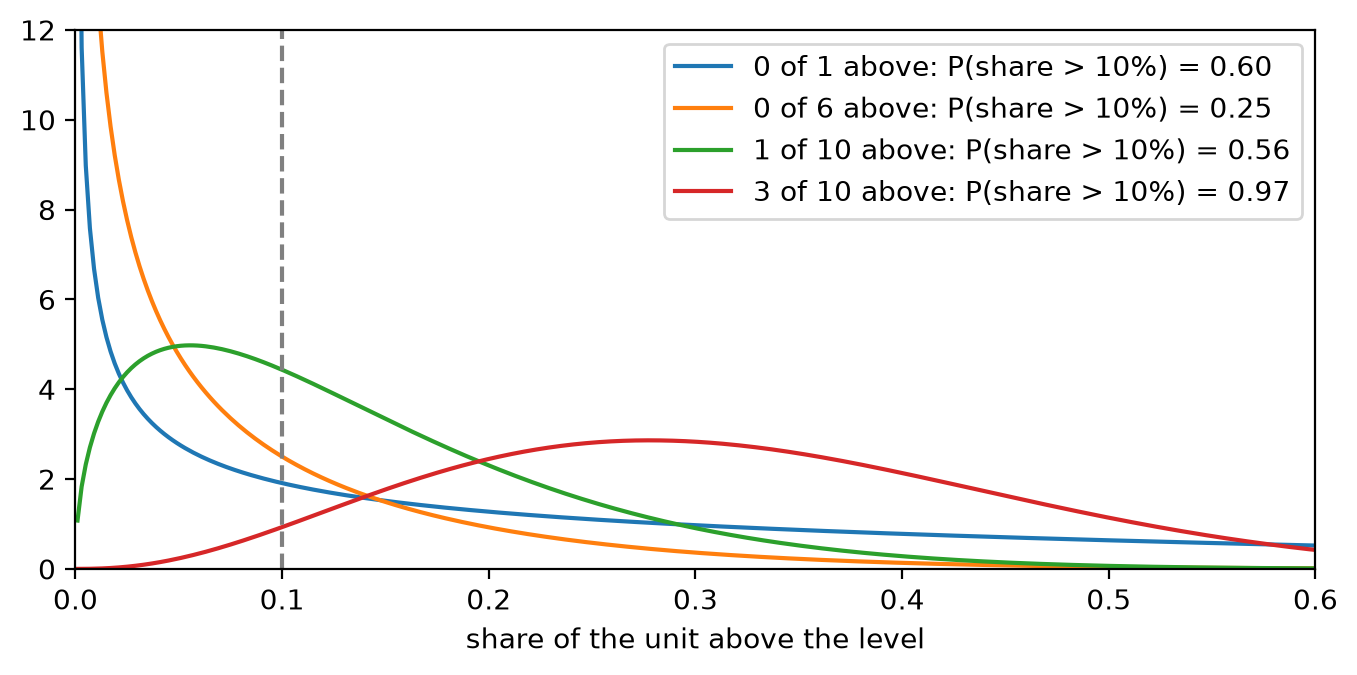

In [ ]:
grid = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
for k, n in [(0, 1), (0, 6), (1, 10), (3, 10)]:
    p = beta.sf(0.1, 0.5 + k, 0.5 + n - k)
    ax.plot(grid, beta.pdf(grid, 0.5 + k, 0.5 + n - k), label=f'{k} of {n} above: P(share > 10%) = {p:.2f}')
ax.axvline(0.1, color='grey', ls='--')
ax.set(xlabel='share of the unit above the level', ylim=(0, 12), xlim=(0, 0.6))
ax.legend();

With a few samples, the distribution stays wide. After 6 samples with none above the level, there is still a 25% chance the unit should be restricted.

## `bayes`

`bayes` treats the smaller of P(share > 10%) and its complement as the probability that the unit's decision is wrong, and splits the budget in proportion to it. Without a prior, it beat equal allocation on every ground truth in the experiments.

## The prior problem

A prior adds what an airborne survey says before any sample. A unit whose survey shows 30% of it above the level, with the survey worth 20 samples, starts from Beta(0.5 + 6, 0.5 + 14). `bayes` then sees almost no chance of a wrong decision, and gives the unit nothing beyond its compulsory sample. But the dashboard ignores the survey and decides from the samples alone. With one sample, the unit is restricted only if that sample is above the level:

In [ ]:
a0, b0 = 0.5 + 20 * 0.3, 0.5 + 20 * 0.7
{'bayes: P(decision wrong)': round(float(min(beta.sf(0.1, a0, b0), beta.cdf(0.1, a0, b0))), 3),
 'dashboard with 1 sample: P(wrong)': round(expected_wrong(0, 0, 1, a0, b0), 3),
 'dashboard with 5 samples: P(wrong)': round(expected_wrong(0, 0, 5, a0, b0), 3)}

{'bayes: P(decision wrong)': 0.005,
 'dashboard with 1 sample: P(wrong)': 0.686,
 'dashboard with 5 samples: P(wrong)': 0.187}

`bayes` answers the wrong question: how likely the unit should be restricted, not how likely the dashboard's rule will get it wrong. In the experiments, any prior, even the ground truth itself, made `bayes` worse for this reason.

## `expected_wrong`

`expected_wrong(k, n, m, a0, b0)` answers the right question. For each possible `share`, the `m` next samples bring a binomial number of exceedances, which sets the dashboard's decision. The decision is wrong when it differs from what `share` calls for. The result averages over the beta distribution of `share`. It therefore sees the sawtooth of notebook 4:

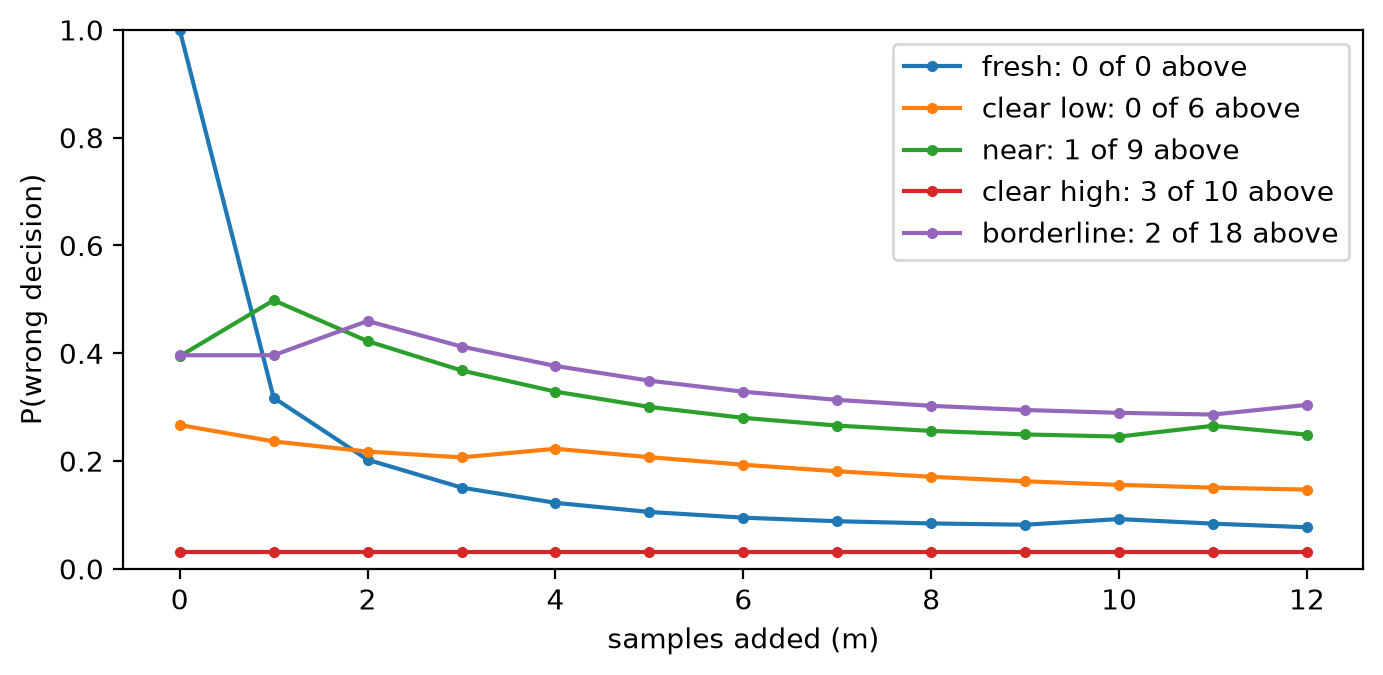

In [ ]:
units = {'fresh': (0, 0), 'clear low': (0, 6), 'near': (1, 9), 'clear high': (3, 10), 'borderline': (2, 18)}
m = np.arange(0, 13)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, (k, n) in units.items():
    ax.plot(m, [expected_wrong(k, n, mm) for mm in m], 'o-', ms=3, label=f'{name}: {k} of {n} above')
ax.set(xlabel='samples added (m)', ylabel='P(wrong decision)', ylim=(0, 1))
ax.legend();

- `fresh` has no samples: undefined, so wrong. The first samples help a lot.
- `near` (1 of 9) is restricted. A 10th sample makes things worse, because the rule then needs 2 exceedances. It takes three more samples to do better than now.
- `borderline` (2 of 18) gains nothing from a 19th sample, and loses with a 20th, which raises the count needed to 3.
- `clear high` (3 of 10) stays restricted whatever the next samples show, so samples cannot change its decision.

## `voi`

`voi` gives each sample, one at a time, to the unit whose probability of a wrong decision falls fastest: the largest average drop per sample over the next 1 to `horizon` samples, 10 by default. Looking several samples ahead lets it see past a jump of the sawtooth. Splitting 20 samples over the five toy units:

In [ ]:
toy_units = pd.DataFrame(index=pd.Index(list(units), name='loc_id'))
values = [(u, 0.9) for u, (k, n) in units.items() for _ in range(k)] + [(u, 0.5) for u, (k, n) in units.items() for _ in range(n - k)]
toy_samples = pd.DataFrame({'value': [v for _, v in values]}, index=pd.Index([u for u, _ in values], name='loc_id'))
pd.DataFrame({'P(wrong) now': [round(expected_wrong(k, n, 0), 3) for k, n in units.values()],
              'bayes': bayes(0.8, 0.1, 0)(toy_samples, toy_units, 20, np.random.default_rng(0)),
              'voi': voi(0.8, 0.1, min_total=1)(toy_samples, toy_units, 20, np.random.default_rng(0))}, index=toy_units.index)

,P(wrong) now,bayes,voi
loc_id,,,
fresh,1.000,3,5
clear low,0.267,4,2
near,0.395,6,7
clear high,0.031,1,0
borderline,0.396,6,6


`voi` gives `clear high` nothing, since its decision cannot change, and `clear low` fewer than `bayes` (2 against 4). It gives `borderline` as many samples as `bayes`: looking 10 samples ahead, it sees the probability of a wrong decision fall after the jump at 20 samples. With a look-ahead of 5, `voi` gave `borderline` only 3 samples, which left such units restricted needlessly in the plume experiments.

## What the experiments found

Wrong decisions after six rounds of 150 samples, mean of 20 seeds (from `scoring-plan.md`, step 5):

| Truth | equal | bayes | voi | voi, perfect prior | voi, survey prior worth 4 samples | oracle |
|---|---|---|---|---|---|---|
| `ground-truth-02` at 0.473 | 10.0 | 7.8 | 9.1 | 4.0 | 9.2 | 6.5 |
| Fukushima plume window at 4.9 µSv/h | 7.4 | 6.2 | 6.3 | 4.0 | 6.8 | 5.6 |
| Fukushima window near the plant at 14.8 µSv/h | 1.8 | 1.2 | 1.4 | 0.0 | 0.8 | 0.2 |

- With a good prior, `voi` makes the fewest wrong decisions of any strategy, fewer than the decision oracle, which is a rule of thumb, not the best possible allocation.
- With realistic priors, the gain depends on how much the prior is trusted. A poor prior worth 20 samples did worse than equal allocation in the plume window.
- Without a prior, `voi` is no better than `bayes`. These results used a look-ahead of 5. On ten synthetic plumes, a look-ahead of 10 lowers `voi`'s wrong decisions in most settings, by keeping units with an early exceedance in the sample ("`voi`'s horizon" in `_scoring_experiments.ipynb`).